In [55]:
import pandas as pd

In [56]:
df=pd.read_csv('polynomial_regression_practice.csv')

In [57]:
df.head()

,Advertising_Spend,Sales
0,8.12,72.20
1,19.06,288.20
2,14.91,190.88
3,12.37,114.54
4,3.96,25.46


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Advertising_Spend  100 non-null    float64
 1   Sales              100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


In [59]:
import seaborn as sns

<Axes: xlabel='Advertising_Spend', ylabel='Sales'>

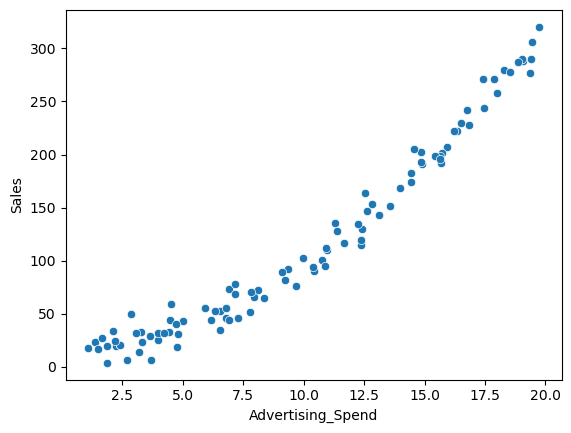

In [60]:
sns.scatterplot(data=df,x='Advertising_Spend',y='Sales')

In [61]:
df.corr(numeric_only=True)

,Advertising_Spend,Sales
Advertising_Spend,1.00000,0.96953
Sales,0.96953,1.00000


In [62]:
X=df.drop(columns='Sales')
y=df['Sales']

In [63]:
from sklearn.model_selection import train_test_split

In [64]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [65]:
from sklearn.preprocessing import PolynomialFeatures

In [66]:
from sklearn.pipeline import Pipeline

In [67]:
from sklearn.linear_model import LinearRegression

In [68]:
pipeline=Pipeline(
    steps=[
        ('poly',PolynomialFeatures(degree=2)),
        ('model',LinearRegression())
    ]
)

In [69]:
pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Advertising_Spend']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [70]:
from sklearn.metrics import r2_score,mean_absolute_error,root_mean_squared_error

In [71]:
# Train eval
y_train_pred=pipeline.predict(X_train)
print(r2_score(y_train,y_train_pred))
print(mean_absolute_error(y_train,y_train_pred))
print(root_mean_squared_error(y_train,y_train_pred))

0.9852601211221189
8.440854450490235
10.831482379206303


In [72]:
# Test eval
y_test_pred=pipeline.predict(X_test)
print(r2_score(y_test,y_test_pred))
print(mean_absolute_error(y_test,y_test_pred))
print(root_mean_squared_error(y_test,y_test_pred))

0.9894576108133466
6.9353627501817545
9.568443190775687
